# Part 1, extension 3b: the network draws the map, year by year

The trained network from notebook 02, unchanged, looks at every 640 m square of the Madre de Dios window from notebook 07. For each year from 2019 to 2024 it compares that year's image with 2018 and says "lost" or "stable". The result is one map frame per year, which together form a time-lapse.

**How it is checked.** Hansen's loss maps are the reference, with the same label rules as training. For the frame of year *t*, a square counts as truly "lost" if at least 10% of it lost forest between 2019 and the year before *t*. A square counts as truly "stable" if it had almost no loss at any time up to *t*. Squares in between are shown on the map but not scored, just as such patches were left out of training.

**Limits to keep in mind.**
- Neighbouring squares are not independent, so these scores are descriptive. They don't come with the confidence ranges used in notebook 06.
- Hansen v1.11 ends in 2023. For the 2024 frame, clearing that happened during 2024 can't be checked, so some 2024 "false alarms" may be real clearing.
- The 2019 frame is only one year after 2018, and the training pairs were five years apart. It shows how the network behaves with very little time for change.

## 1. Settings

In [19]:
import os
import json
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Must match notebook 02 exactly
PATCH_DIR = "../data/raw/part1_patches"
INDEX_CSV = "../data/cleaned/part1_patch_index.csv"
OUT_DIR = "../outputs"
MODEL_PATH = "../models/part1_resnet18.pt"
PRED_CSV = "../outputs/part1_test_predictions.csv"
SEED = 42
SPLIT = (0.70, 0.15, 0.15)
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]
CHANNELS = [f"{b}_{t}" for t in ("before", "after") for b in BANDS]


# The map from notebook 07
MAP_DIR = "../data/raw/part1_map"
GRID_JSON = "../data/cleaned/part1_map_grid.json"
TILES_CSV = "../data/cleaned/part1_map_tiles.csv"
FRAME_DIR = "../outputs/part1_map_frames"

# Label rules from notebook 01, unchanged
LOST_MIN_FRACTION = 0.10
LOST_BEFORE_MAX = 0.05
STABLE_MIN_TREECOVER = 50
STABLE_MAX_LOSS = 0.01
MAX_NODATA_FRACTION = 0.05
FOREST_SHOW_MIN = 0.5    # a square is mapped if at least half of it was forest at the end of 2018
TILE_KM2 = (0.64) ** 2   # ground area of one square

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print("Running on", device)
os.makedirs(FRAME_DIR, exist_ok=True)

Running on mps


## 2. Rebuild the training scaling and the trained model

The next four cells are copied unchanged from notebook 06. The last one stops the notebook if the model doesn't reproduce notebook 02's saved results.

In [20]:
index = pd.read_csv(INDEX_CSV)

Xs, ys, ids = [], [], []
for fname in sorted(os.listdir(PATCH_DIR)):
    if fname.endswith(".npz"):
        z = np.load(os.path.join(PATCH_DIR, fname), allow_pickle=True)
        Xs.append(z["X"]); ys.append(z["y"]); ids.extend(z["patch_id"].tolist())
X = np.concatenate(Xs)                      # (patches, 12, 64, 64), whole numbers (uint16)
meta = index.set_index("patch_id").loc[ids].reset_index()
y = meta["label"].to_numpy(np.int64)        # 0 = stable forest, 1 = forest lost

assert len(X) == len(meta) == len(index), "the .npz files and the index CSV disagree; rerun step 1 sections 7"
assert (np.concatenate(ys) == y).all(), "labels in the .npz files and the index CSV disagree"
assert meta["patch_id"].is_unique
print(f"{len(X)} patches, {X.shape[1]} bands of {X.shape[2]}x{X.shape[3]} pixels")
print(meta.groupby(["country", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

6292 patches, 12 bands of 64x64 pixels
label                             stable  lost
country                                       
Brazil                              1000  1000
Democratic Republic of the Congo    1000   516
India                                455   473
Indonesia                            946   902


In [21]:
def split_blocks(meta, fractions, seed):
    rng = np.random.default_rng(seed)
    part = pd.Series("", index=meta.index)
    for country, g in meta.groupby("country"):
        blocks = g["block"].unique()
        rng.shuffle(blocks)
        share = g.groupby("block").size().loc[blocks].cumsum() / len(g)   # running share of patches
        names = np.where(share <= fractions[0], "train",
                         np.where(share <= fractions[0] + fractions[1], "val", "test"))
        part.loc[g.index] = g["block"].map(dict(zip(blocks, names)))
    return part

n_countries = meta["country"].nunique()
for attempt in range(200):
    meta["split"] = split_blocks(meta, SPLIT, SEED + attempt)
    classes = meta.groupby(["country", "split"])["label"].nunique()
    if len(classes) == n_countries * 3 and (classes == 2).all():
        break
else:
    raise RuntimeError("could not find a block split with both classes everywhere; lower the test share")

assert meta.groupby("block")["split"].nunique().max() == 1, "a block ended up in two groups"
tr = np.where(meta["split"] == "train")[0]
va = np.where(meta["split"] == "val")[0]
te = np.where(meta["split"] == "test")[0]
print(f"Split found on attempt {attempt + 1}: {len(tr)} train, {len(va)} validation, {len(te)} test")
print(meta.groupby(["country", "split", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

Split found on attempt 1: 4312 train, 930 validation, 1050 test
label                                   stable  lost
country                          split              
Brazil                           test      151   154
                                 train     690   701
                                 val       159   145
Democratic Republic of the Congo test      183    62
                                 train     648   383
                                 val       169    71
India                            test       98    84
                                 train     290   327
                                 val        67    62
Indonesia                        test      158   160
                                 train     668   605
                                 val       120   137


/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_13270/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_13270/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_13270/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplic

In [22]:
mean = np.array([X[tr, c].astype(np.float32).mean() for c in range(X.shape[1])], dtype=np.float32)
std = np.array([X[tr, c].astype(np.float32).std() for c in range(X.shape[1])], dtype=np.float32)
MEAN = torch.tensor(mean).view(1, -1, 1, 1).to(device)
STD = torch.tensor(std).view(1, -1, 1, 1).to(device)

def to_batch(idx, augment=False):
    xb = torch.from_numpy(X[idx].astype(np.float32)).to(device)
    xb = (xb - MEAN) / STD
    if augment:
        xb = torch.stack([torch.rot90(x, random.randint(0, 3), dims=(1, 2)) for x in xb])
        flip = torch.rand(len(xb), device=device) < 0.5
        xb[flip] = torch.flip(xb[flip], dims=(3,))
    return xb, torch.from_numpy(y[idx]).to(device)

print(pd.DataFrame({"mean": mean, "std": std}, index=CHANNELS).round(0))

              mean    std
B2_before    972.0  104.0
B3_before    836.0  102.0
B4_before    548.0  114.0
B8_before   2613.0  416.0
B11_before  1408.0  247.0
B12_before   559.0  143.0
B2_after    1011.0  111.0
B3_after     882.0  121.0
B4_after     602.0  159.0
B8_after    2649.0  439.0
B11_after   1535.0  377.0
B12_after    637.0  246.0


In [23]:
def build_model():
    model = resnet18(weights=None)                   # weights come from our saved file below
    old = model.conv1.weight.data                    # (64, 3, 7, 7), filters for red, green, blue
    rgb_for = {0: 2, 1: 1, 2: 0}                     # our B2 = blue, B3 = green, B4 = red
    new = torch.empty(64, len(CHANNELS), 7, 7)
    for c in range(len(CHANNELS)):
        b = c % len(BANDS)
        new[:, c] = old[:, rgb_for[b]] if b in rgb_for else old.mean(dim=1)
    model.conv1 = nn.Conv2d(len(CHANNELS), 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = new * 3 / len(CHANNELS)   # keep the layer's output at the same scale
    model.maxpool = nn.Identity()                    # 64x64 patches are small: skip one shrinking step
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, 2))
    return model

model = build_model().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))   # strict: every layer must match
model.eval()

@torch.no_grad()
def predict(net, idx):
    net.eval()
    probs = []
    for s in range(0, len(idx), 256):
        xb, _ = to_batch(idx[s:s + 256])
        probs.append(F.softmax(net(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

saved = pd.read_csv(PRED_CSV)
assert set(saved["patch_id"]) == set(meta["patch_id"].iloc[te]), \
    "the test patches differ from notebook 02's; the split did not come out the same"
saved = saved.set_index("patch_id").loc[meta["patch_id"].iloc[te]]
p_now = predict(model, te)
gap = np.abs(p_now - saved["prob_lost"].to_numpy())
agree = ((p_now > 0.5).astype(int) == saved["predicted"].to_numpy()).mean()
print(f"Largest difference from the saved probabilities: {gap.max():.4f}")
print(f"Same lost/stable call as notebook 02 on {agree:.1%} of {len(te)} test patches")
print(f"Balanced accuracy now {balanced_accuracy_score(y[te], p_now > 0.5):.3f}")
assert gap.max() < 0.01 and agree >= 0.999, "the model does not reproduce notebook 02's results; stop here"
print("Check 1 passed")

Largest difference from the saved probabilities: 0.0000
Same lost/stable call as notebook 02 on 100.0% of 1050 test patches
Balanced accuracy now 0.938
Check 1 passed


## 3. Cut the map into squares and ask the network

`predict_array()` is copied from notebook 06, including its check against the training-test predictions. Each square gets the six 2018 bands, then the six bands of the later year, in the same order as the training patches.

In [24]:
@torch.no_grad()
def predict_array(arr):
    model.eval()
    probs = []
    for s in range(0, len(arr), 256):
        xb = torch.from_numpy(arr[s:s + 256].astype(np.float32)).to(device)
        xb = (xb - MEAN) / STD
        probs.append(F.softmax(model(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

# Same scaling path as to_batch(): confirm on a few training-test patches before trusting it
assert np.allclose(predict_array(X[te[:50]]), p_now[:50], atol=1e-4), "predict_array does not match to_batch"

grid = json.load(open(GRID_JSON))
tiles = pd.read_csv(TILES_CSV)
R, C, T = grid["rows"], grid["cols"], grid["tile_px"]
assert T == X.shape[2] == X.shape[3], "map squares are not the same size as training patches"
assert len(tiles) == R * C and (tiles["row"] * C + tiles["col"]).tolist() == list(range(R * C)), \
    "the squares table is not in row order"

def squares(mos):
    # (bands, R*T, C*T) -> (R*C, bands, T, T), row by row, the same order as the squares table
    b = mos.shape[0]
    return mos[:, :R * T, :C * T].reshape(b, R, T, C, T).transpose(1, 3, 0, 2, 4).reshape(R * C, b, T, T)

before = squares(np.load(os.path.join(MAP_DIR, f"mosaic_{grid['before_year']}.npy")))
assert before.shape[1] == len(BANDS) + 1
# The reshape must give the same square as plain slicing
r0, c0 = R // 2, C // 3
assert (before[r0 * C + c0] == np.load(os.path.join(MAP_DIR, f"mosaic_{grid['before_year']}.npy"))
        [:, r0 * T:(r0 + 1) * T, c0 * T:(c0 + 1) * T]).all(), "square cutting is wrong"

preds = []
for year in grid["after_years"]:
    after = squares(np.load(os.path.join(MAP_DIR, f"mosaic_{year}.npy")))
    Xm = np.concatenate([before[:, :len(BANDS)], after[:, :len(BANDS)]], axis=1)     # 12 bands, like training
    nodata = 1 - (before[:, -1] * after[:, -1]).mean(axis=(1, 2))                    # both years must have data
    p = predict_array(Xm)
    preds.append(pd.DataFrame({"tile_id": tiles["tile_id"], "year": year, "prob_lost": p.round(4),
                               "predicted": (p > 0.5).astype(int), "nodata_frac": nodata.round(4)}))
    print(f"{year}: {np.mean(nodata > MAX_NODATA_FRACTION):.1%} of squares too cloudy, "
          f"{np.mean(p > 0.5):.1%} called lost")
preds = pd.concat(preds, ignore_index=True)

2019: 0.0% of squares too cloudy, 20.4% called lost
2020: 0.0% of squares too cloudy, 36.7% called lost
2021: 0.0% of squares too cloudy, 49.5% called lost
2022: 0.0% of squares too cloudy, 59.2% called lost
2023: 0.0% of squares too cloudy, 68.1% called lost
2024: 0.0% of squares too cloudy, 73.5% called lost


## 4. Score each frame against Hansen

Same rules as notebook 01, with the loss window ending the year before each frame. Only squares that were mostly forest at the end of 2018 and have clear images in both years are scored.

In [25]:
def truth_for(year):
    last = min(year - 1, 2023)
    lost_frac = sum((tiles[f"lostF_{y}"] for y in range(2019, last + 1)), start=pd.Series(0.0, index=tiles.index))
    any_upto = tiles[f"lostA_upto_{min(year, 2023)}"]
    lost = (lost_frac >= LOST_MIN_FRACTION) & (tiles["lost_before_frac"] < LOST_BEFORE_MAX)
    stable = (any_upto < STABLE_MAX_LOSS) & (tiles["treecover_mean"] >= STABLE_MIN_TREECOVER)
    return np.select([lost, stable], [1, 0], default=-1), lost_frac

rows, frames = [], {}
for year in grid["after_years"]:
    t, lost_frac = truth_for(year)
    p = preds[preds.year == year].set_index("tile_id").loc[tiles["tile_id"]]
    shown = (tiles["forest2018_frac"].to_numpy() >= FOREST_SHOW_MIN) & (p["nodata_frac"].to_numpy() <= MAX_NODATA_FRACTION)
    scored = shown & (t >= 0)
    yt, yp = t[scored], p["predicted"].to_numpy()[scored]
    row = {"year": year, "squares_mapped": int(shown.sum()), "squares_scored": int(scored.sum()),
           "true_lost": int((yt == 1).sum()), "true_stable": int((yt == 0).sum()),
           "caught": int(((yt == 1) & (yp == 1)).sum()), "false_alarms": int(((yt == 0) & (yp == 1)).sum()),
           "network_lost_km2": float(p["predicted"].to_numpy()[shown].sum() * TILE_KM2),
           "hansen_lost_km2": float((lost_frac.to_numpy()[shown] * TILE_KM2).sum())}
    row["recall_lost"] = row["caught"] / row["true_lost"] if row["true_lost"] else float("nan")
    row["false_alarm_rate"] = row["false_alarms"] / row["true_stable"] if row["true_stable"] else float("nan")
    row["balanced_accuracy"] = (balanced_accuracy_score(yt, yp) if len(np.unique(yt)) == 2 else float("nan"))
    rows.append(row)
    frames[year] = {"prob": p["prob_lost"].to_numpy(), "pred": p["predicted"].to_numpy(),
                    "shown": shown, "hansen_lost": lost_frac.to_numpy() >= LOST_MIN_FRACTION}
score = pd.DataFrame(rows).set_index("year")
print(score.round(3).to_string())
print("\nnetwork_lost_km2 counts whole squares called lost; hansen_lost_km2 adds up the cleared share of each square,"
      " so the network's area is expected to be larger.")

      squares_mapped  squares_scored  true_lost  true_stable  caught  false_alarms  network_lost_km2  hansen_lost_km2  recall_lost  false_alarm_rate  balanced_accuracy
year                                                                                                                                                                   
2019            1552             617          0          617       0             5           108.134            0.000          NaN             0.008                NaN
2020            1552             565         28          537      28             4           215.040           13.641        1.000             0.007              0.996
2021            1552             517         75          442      73             8           292.864           30.034        0.973             0.018              0.978
2022            1552             495        149          346     146             6           362.086           53.106        0.980             0.017            

## 5. Draw the frames

Each frame shows that year's satellite image in natural colour. Squares the network calls lost are filled in orange. Squares that weren't mostly forest in 2018 (rivers, towns, older clearings) are greyed out. The right-hand panel shows Hansen's map for the same years, for comparison. All frames use one colour stretch, taken from the 2018 image and set band by band, so the years can be compared and the haze doesn't turn everything blue.

Saved 6 frames and part1_map_timelapse.gif


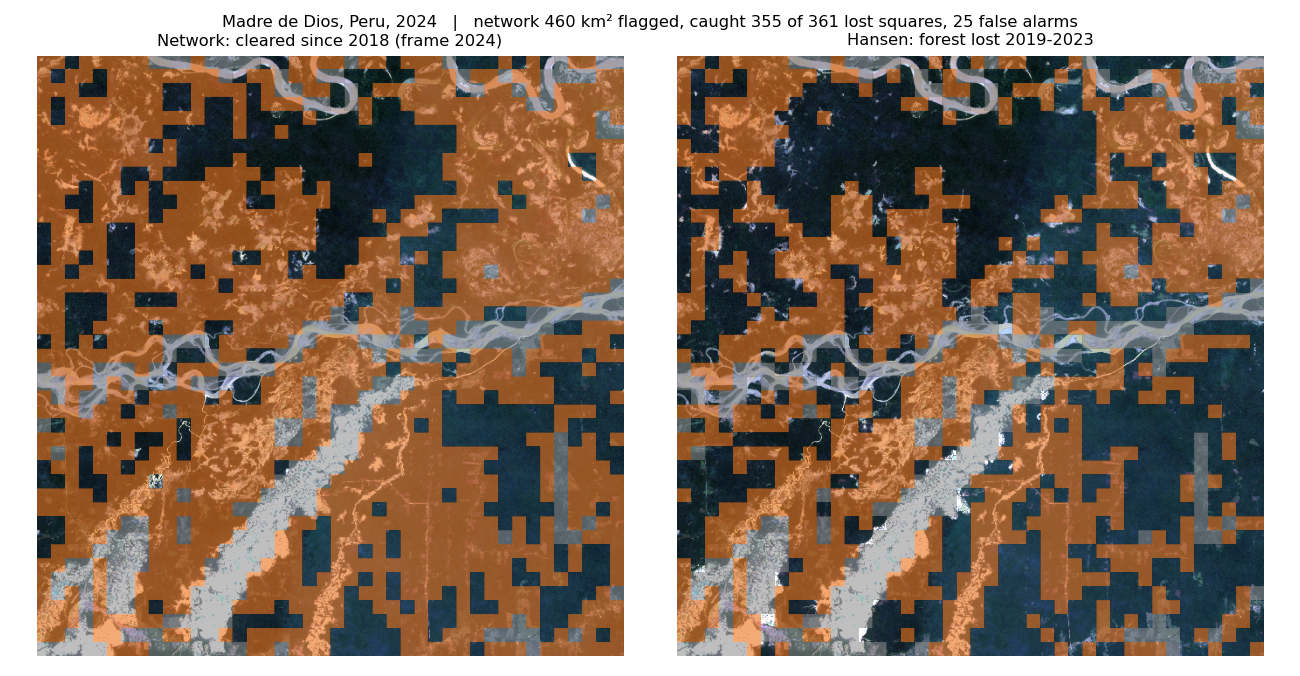

In [26]:
STEP = 4   # draw every 4th pixel to keep the files small
base = np.load(os.path.join(MAP_DIR, f"mosaic_{grid['before_year']}.npy"))
lo = np.percentile(base[[2, 1, 0]][:, ::STEP, ::STEP], 2, axis=(1, 2))
hi = np.percentile(base[[2, 1, 0]][:, ::STEP, ::STEP], 98, axis=(1, 2))

def natural_colour(mos):
    img = mos[[2, 1, 0], ::STEP, ::STEP].transpose(1, 2, 0).astype(float)   # B4, B3, B2
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)

def overlay(flag, shown):
    flag, shown = np.asarray(flag).reshape(R, C), np.asarray(shown).reshape(R, C)   # squares are in row order
    o = np.zeros((R, C, 4))
    o[~shown] = (0.55, 0.55, 0.55, 0.55)            # not mapped
    o[shown & flag] = (0.93, 0.45, 0.10, 0.60)      # lost
    return np.kron(o, np.ones((T // STEP, T // STEP, 1)))

paths = []
for year in grid["after_years"]:
    f = frames[year]
    img = natural_colour(np.load(os.path.join(MAP_DIR, f"mosaic_{year}.npy")))
    fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
    for ax, flag, title in [(axes[0], f["pred"] == 1, f"Network: cleared since 2018 (frame {year})"),
                            (axes[1], f["hansen_lost"], f"Hansen: forest lost 2019-{min(year - 1, 2023)}"
                                                         if year > 2019 else "Hansen: nothing counted yet")]:
        ax.imshow(img)
        ax.imshow(overlay(flag, f["shown"]))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    s = score.loc[year]
    fig.suptitle(f"Madre de Dios, Peru, {year}   |   network {s.network_lost_km2:.0f} km² flagged, "
                 f"caught {s.caught:.0f} of {s.true_lost:.0f} lost squares, {s.false_alarms:.0f} false alarms",
                 fontsize=9)
    plt.tight_layout()
    path = os.path.join(FRAME_DIR, f"frame_{year}.png")
    plt.savefig(path, dpi=130)
    plt.close(fig)
    paths.append(path)

from PIL import Image
imgs = [Image.open(p).convert("RGB") for p in paths]
imgs[0].save("../outputs/part1_map_timelapse.gif", save_all=True, append_images=imgs[1:], duration=1200, loop=0)
print("Saved", len(paths), "frames and part1_map_timelapse.gif")
Image.open(paths[-1])

## 6. Save

In [27]:
out = preds.merge(tiles[["tile_id", "row", "col", "lon", "lat", "forest2018_frac"]], on="tile_id")
out.to_csv("../outputs/part1_map_predictions.csv", index=False)
result = {
    "region": "Madre de Dios, Peru (never seen in training)",
    "window": grid["window"], "squares": int(R * C), "square_size_m": 640,
    "model": "notebook 02 ResNet-18, unchanged; scaled with training statistics",
    "check1_reproduces_notebook02": {"max_prob_gap": float(gap.max()), "same_call_share": float(agree)},
    "rules": "notebook 01 label rules; loss window 2019 to the year before each frame; Hansen v1.11 (to 2023)",
    "by_year": {int(y): {k: (None if pd.isna(v) else float(v)) for k, v in r.items()} for y, r in score.iterrows()},
}
with open("../outputs/part1_map_metrics.json", "w") as f:
    json.dump(result, f, indent=2)
print("Saved part1_map_predictions.csv and part1_map_metrics.json")

Saved part1_map_predictions.csv and part1_map_metrics.json


## Sources and credits

- Hansen, M. C. et al. (2013). High-Resolution Global Maps of 21st-Century Forest Cover Change. *Science* 342, 850–853. Data: University of Maryland, CC BY 4.0.
- Contains modified Copernicus Sentinel data (2018–2024).
- Pasquarella, V. J. et al. (2023). Cloud Score+ for Sentinel-2.